# Chapter 4 Capstone — Consumption Risk, Risk Aversion, and Equilibrium Pricing

## Financial Question

How does risk aversion affect equilibrium asset prices, the risk-free rate, and the expected return premium on a risky payoff when consumption growth differs across future states?

This notebook studies a simple two-state representative-agent economy. The agent has CRRA preferences, and asset prices are determined by the stochastic discount factor implied by consumption growth.

The analysis has four objectives:

1. construct the pricing kernel from consumption growth and preferences;
2. compute the implied risk-free rate and a risky-asset premium proxy;
3. calibrate the coefficient of relative risk aversion, $\gamma$, to an illustrative target premium range;
4. compare low- and high-risk-aversion economies and interpret the difference economically.

The model uses two future states:

- **Up state:** relatively strong consumption growth;
- **Down state:** relatively weak consumption growth.

The physical probabilities are

$$
P=(0.5,0.5),
$$

and the consumption-growth vector is

$$
g=(1.2,0.8).
$$

The representative agent has CRRA marginal utility

$$
u'(c)=c^{-\gamma},
$$

so the pricing kernel is

$$
\boxed{
m_s=\beta g_s^{-\gamma}
}
$$

where $\beta$ is the time-preference factor and $\gamma$ is the coefficient of relative risk aversion.

A risky asset pays

$$
X_1=(1.4,0.8),
$$

so it performs best in the high-consumption state and pays less in the low-consumption state.

For calibration, this notebook uses an illustrative target premium range of

$$
\boxed{10\%\text{ to }12\%}.
$$

This range is a modeling choice for demonstrating calibration; it is not presented as an empirical market estimate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

beta = 0.95

P = np.array([0.5, 0.5])
growth = np.array([1.2, 0.8])
risky_payoff = np.array([1.4, 0.8])

target_premium_low = 0.10
target_premium_high = 0.12

print("Probability sum:", P.sum())
print("Consumption growth:", growth)
print("Risky payoff:", risky_payoff)
print(
    "Target premium range:",
    f"{target_premium_low:.0%} to {target_premium_high:.0%}",
)

Probability sum: 1.0
Consumption growth: [1.2 0.8]
Risky payoff: [1.4 0.8]
Target premium range: 10% to 12%


## 1. CRRA Preferences and the Pricing Kernel

The representative agent has constant relative risk aversion (CRRA) preferences.

For

$$
\gamma \neq 1,
$$

CRRA utility is

$$
u(c)
=
\frac{c^{1-\gamma}}{1-\gamma},
$$

with marginal utility

$$
u'(c)=c^{-\gamma}.
$$

The parameter

$$
\gamma>0
$$

is the coefficient of relative risk aversion.

A larger $\gamma$ means that marginal utility reacts more strongly to differences in consumption across states.

For a two-date economy, the stochastic discount factor or pricing kernel is

$$
m_s
=
\beta
\frac{u'(c_{1,s})}{u'(c_0)}.
$$

With CRRA preferences and consumption growth

$$
g_s=\frac{c_{1,s}}{c_0},
$$

this becomes

$$
\boxed{
m_s=\beta g_s^{-\gamma}.
}
$$

The economic interpretation is central:

$$
\text{low consumption growth}
\rightarrow
\text{high marginal utility}
\rightarrow
\text{high pricing kernel}.
$$

A payoff delivered in a low-consumption state therefore receives greater valuation weight.

The initial baseline uses

$$
\gamma=2.
$$

This is a starting parameter for understanding the model, not the final calibrated value.

In [2]:
gamma_baseline = 2.0

pricing_kernel = beta * growth ** (-gamma_baseline)
state_prices = P * pricing_kernel

baseline_table = pd.DataFrame(
    {
        "State": ["Up", "Down"],
        "Probability": P,
        "Consumption Growth": growth,
        "Pricing Kernel": pricing_kernel,
        "State Price": state_prices,
    }
)

print("Baseline gamma:", gamma_baseline)
print("Pricing kernel:", pricing_kernel)
print("State prices:", state_prices)

baseline_table

Baseline gamma: 2.0
Pricing kernel: [0.6597 1.4844]
State prices: [0.3299 0.7422]


,State,Probability,Consumption Growth,Pricing Kernel,State Price
0,Up,0.5,1.2,0.659722,0.329861
1,Down,0.5,0.8,1.484375,0.742187


## 2. Implied Risk-Free Rate

A risk-free asset pays the same amount in every future state.

Consider a claim with payoff

$$
B_1=(1,1).
$$

Using state prices, its current value is

$$
B_0
=
\sum_s \psi_s.
$$

Because

$$
\psi_s=p_sm_s,
$$

this is equivalent to

$$
B_0
=
\mathbb E_P[m].
$$

The gross risk-free return is therefore

$$
\boxed{
R_f
=
\frac{1}{\mathbb E_P[m]}.
}
$$

The corresponding net risk-free rate is

$$
\boxed{
r_f=R_f-1.
}
$$

This result can also be derived from the Euler equation

$$
1=\mathbb E_P[mR_f].
$$

Because $R_f$ is identical across states,

$$
1
=
R_f\mathbb E_P[m],
$$

which again implies

$$
R_f
=
\frac{1}{\mathbb E_P[m]}.
$$

In [3]:
expected_kernel = np.dot(P, pricing_kernel)

riskfree_payoff = np.ones_like(P)
riskfree_price = np.dot(state_prices, riskfree_payoff)

R_f = 1.0 / expected_kernel
r_f = R_f - 1.0

euler_rf = np.dot(
    P,
    pricing_kernel * R_f,
)

print("E[m]:", expected_kernel)
print("Risk-free asset price:", riskfree_price)
print("Gross risk-free return R_f:", R_f)
print("Net risk-free rate r_f:", r_f)
print("Euler check E[m * R_f]:", euler_rf)

E[m]: 1.0720486111111112
Risk-free asset price: 1.0720486111111112
Gross risk-free return R_f: 0.9327935222672065
Net risk-free rate r_f: -0.06720647773279353
Euler check E[m * R_f]: 0.9999999999999999


## 3. Risky-Asset Pricing and the Equity-Premium Proxy

The risky asset has future payoff

$$
X_1=(1.4,0.8).
$$

It pays more in the Up state and less in the Down state.

Its current equilibrium price is determined by the pricing kernel:

$$
\boxed{
X_0
=
\mathbb E_P[mX_1].
}
$$

Equivalently, using state prices,

$$
X_0
=
\sum_s \psi_s X_{1,s}.
$$

Once $X_0$ is known, the state-dependent gross returns are

$$
\boxed{
R_{1,s}
=
\frac{X_{1,s}}{X_0}.
}
$$

The expected gross risky return under the physical probability measure is

$$
\mathbb E_P[R_1],
$$

and the expected net risky return is

$$
\mathbb E_P[R_1]-1.
$$

This notebook defines the model-implied equity-premium proxy as

$$
\boxed{
\pi
=
\mathbb E_P[R_1]-R_f.
}
$$

The risky payoff is relatively weak in the low-consumption Down state, where the pricing kernel is highest. Therefore its return must compensate the representative agent for exposure to consumption risk.

In [4]:
risky_price = np.dot(
    state_prices,
    risky_payoff,
)

risky_returns = risky_payoff / risky_price

expected_risky_return = np.dot(
    P,
    risky_returns,
)

expected_risky_rate = (
    expected_risky_return - 1.0
)

premium_proxy = (
    expected_risky_return - R_f
)

euler_risky = np.dot(
    P,
    pricing_kernel * risky_returns,
)

print("Risky asset price X0:", risky_price)
print("State gross returns:", risky_returns)
print(
    "Expected gross risky return:",
    expected_risky_return,
)
print(
    "Expected net risky rate:",
    expected_risky_rate,
)
print("Equity-premium proxy:", premium_proxy)
print(
    "Euler check E[m * R1]:",
    euler_risky,
)

Risky asset price X0: 1.0555555555555554
State gross returns: [1.3263 0.7579]
Expected gross risky return: 1.0421052631578949
Expected net risky rate: 0.04210526315789487
Equity-premium proxy: 0.1093117408906884
Euler check E[m * R1]: 1.0


## 4. Calibrating Relative Risk Aversion

The baseline calculation used

$$
\gamma=2
$$

as an initial parameter choice.

The capstone now treats $\gamma$ as an unknown preference parameter to be calibrated.

For each candidate value of $\gamma$, the model generates

$$
m_s(\gamma)
=
\beta g_s^{-\gamma},
$$

which determines the risk-free return

$$
R_f(\gamma)
=
\frac{1}{\mathbb E_P[m(\gamma)]},
$$

the risky-asset price

$$
X_0(\gamma)
=
\mathbb E_P[m(\gamma)X_1],
$$

the risky return

$$
R_1(\gamma)
=
\frac{X_1}{X_0(\gamma)},
$$

and therefore the premium proxy

$$
\pi(\gamma)
=
\mathbb E_P[R_1(\gamma)]
-
R_f(\gamma).
$$

The illustrative target premium range is

$$
10\%\le\pi(\gamma)\le12\%.
$$

For a single point estimate, the midpoint of this range is used:

$$
\boxed{
\pi_{\text{target}}=11\%.
}
$$

Calibration therefore means finding a value of $\gamma$ whose model-implied premium is as close as possible to $11\%$ while also checking that it lies inside the broader target range.

In [5]:
def model_quantities(gamma):
    """Return equilibrium quantities for a given CRRA parameter gamma."""
    m = beta * growth ** (-gamma)

    expected_m = np.dot(P, m)
    R_f_gamma = 1.0 / expected_m

    risky_price_gamma = np.dot(
        P,
        m * risky_payoff,
    )

    risky_returns_gamma = (
        risky_payoff / risky_price_gamma
    )

    expected_risky_return_gamma = np.dot(
        P,
        risky_returns_gamma,
    )

    premium_gamma = (
        expected_risky_return_gamma
        - R_f_gamma
    )

    return {
        "gamma": gamma,
        "pricing_kernel": m,
        "R_f": R_f_gamma,
        "r_f": R_f_gamma - 1.0,
        "risky_price": risky_price_gamma,
        "expected_risky_return": expected_risky_return_gamma,
        "premium": premium_gamma,
    }

In [6]:
baseline_check = model_quantities(2.0)

print(
    "Premium at gamma=2:",
    baseline_check["premium"],
)
print(
    "Matches direct calculation:",
    np.isclose(
        baseline_check["premium"],
        premium_proxy,
    ),
)

Premium at gamma=2: 0.1093117408906884
Matches direct calculation: True


### Calibration Grid

A transparent grid search is used to calibrate the CRRA coefficient.

The candidate range is

$$
0.5\le\gamma\le4.0,
$$

with increments of

$$
0.01.
$$

For each candidate value, the model recomputes the pricing kernel, risk-free return, risky-asset price, expected risky return, and premium proxy.

A candidate is considered to fall inside the calibration region when

$$
0.10
\le
\pi(\gamma)
\le
0.12.
$$

For a single point calibration, the selected value minimizes

$$
\left|
\pi(\gamma)-0.11
\right|.
$$

This procedure separates the broader acceptable parameter region from the single value that most closely matches the midpoint target.

In [7]:
gamma_grid = np.arange(
    0.50,
    4.01,
    0.01,
)

calibration_rows = []

for gamma_value in gamma_grid:
    result = model_quantities(gamma_value)

    calibration_rows.append(
        {
            "gamma": gamma_value,
            "risk_free_rate": result["r_f"],
            "risky_price": result["risky_price"],
            "expected_risky_return": (
                result["expected_risky_return"]
            ),
            "premium": result["premium"],
        }
    )

calibration_table = pd.DataFrame(
    calibration_rows
)

in_target_range = calibration_table[
    (
        calibration_table["premium"]
        >= target_premium_low
    )
    & (
        calibration_table["premium"]
        <= target_premium_high
    )
].copy()

target_midpoint = (
    target_premium_low
    + target_premium_high
) / 2.0

best_index = (
    calibration_table["premium"]
    .sub(target_midpoint)
    .abs()
    .idxmin()
)

calibrated_row = calibration_table.loc[
    best_index
]

print(
    "First gamma in target range:",
    in_target_range["gamma"].iloc[0],
)
print(
    "Last gamma in target range:",
    in_target_range["gamma"].iloc[-1],
)
print(
    "Point-calibrated gamma:",
    calibrated_row["gamma"],
)
print(
    "Implied premium:",
    calibrated_row["premium"],
)

First gamma in target range: 1.8000000000000012
Last gamma in target range: 2.2500000000000018
Point-calibrated gamma: 2.0200000000000014
Implied premium: 0.1101903434578263


### Calibration Result

The grid search identifies an acceptable risk-aversion region of approximately

$$
\boxed{
1.80\le\gamma\le2.25
}
$$

for the illustrative premium range of 10% to 12%.

Using the midpoint target of 11%, the point-calibrated value is

$$
\boxed{
\gamma^*=2.02.
}
$$

At this value, the model-implied premium is approximately

$$
\boxed{
11.02\%.
}
$$

The point estimate should not be interpreted as a uniquely identified empirical preference parameter. It is the value within this stylized model and chosen calibration grid that most closely matches the illustrative 11% target.

In [8]:
comparison_gammas = [
    1.80,
    2.00,
    float(calibrated_row["gamma"]),
    2.25,
]

comparison_rows = []

for gamma_value in comparison_gammas:
    result = model_quantities(gamma_value)

    comparison_rows.append(
        {
            "Gamma": gamma_value,
            "Risk-Free Rate": result["r_f"],
            "Risky Asset Price": result["risky_price"],
            "Expected Risky Return": (
                result["expected_risky_return"] - 1.0
            ),
            "Premium Proxy": result["premium"],
        }
    )

calibration_summary = pd.DataFrame(
    comparison_rows
)

calibration_summary["Risk-Free Rate"] = (
    calibration_summary["Risk-Free Rate"]
    .map(lambda x: f"{x:.2%}")
)

calibration_summary["Risky Asset Price"] = (
    calibration_summary["Risky Asset Price"]
    .map(lambda x: f"{x:.4f}")
)

calibration_summary["Expected Risky Return"] = (
    calibration_summary["Expected Risky Return"]
    .map(lambda x: f"{x:.2%}")
)

calibration_summary["Premium Proxy"] = (
    calibration_summary["Premium Proxy"]
    .map(lambda x: f"{x:.2%}")
)

calibration_summary

,Gamma,Risk-Free Rate,Risky Asset Price,Expected Risky Return,Premium Proxy
0,1.80,-4.93%,1.0468,5.08%,10.02%
1,2.00,-6.72%,1.0556,4.21%,10.93%
2,2.02,-6.90%,1.0565,4.11%,11.02%
3,2.25,-9.09%,1.0690,2.90%,11.98%


## 5. Two Worlds: Low and High Risk Aversion

To isolate the economic effect of risk aversion, consider two economies that are identical except for the CRRA coefficient.

The **low-risk-aversion world** uses

$$
\gamma_L=1,
$$

while the **high-risk-aversion world** uses

$$
\gamma_H=4.
$$

Both worlds have the same:

- time-preference factor,
- physical state probabilities,
- consumption-growth process,
- and risky-asset payoff.

Therefore any difference in prices or implied returns is generated solely by the change in risk aversion.

The comparison focuses on:

1. the Up- and Down-state pricing kernels;
2. the relative pricing weight placed on the Down state;
3. the implied risk-free rate;
4. the risky-asset price;
5. the expected risky return;
6. the resulting premium proxy.

This provides a direct economic comparison of how stronger aversion to consumption risk changes equilibrium valuation.

In [9]:
world_specs = {
    "Low risk aversion": 1.0,
    "High risk aversion": 4.0,
}

world_rows = []

for world_name, gamma_value in world_specs.items():
    result = model_quantities(gamma_value)
    m = result["pricing_kernel"]

    world_rows.append(
        {
            "World": world_name,
            "Gamma": gamma_value,
            "m_up": m[0],
            "m_down": m[1],
            "Down/Up Kernel Ratio": m[1] / m[0],
            "Risk-Free Rate": result["r_f"],
            "Risky Asset Price": result["risky_price"],
            "Expected Risky Return": (
                result["expected_risky_return"] - 1.0
            ),
            "Premium Proxy": result["premium"],
        }
    )

worlds = pd.DataFrame(world_rows)

worlds_display = worlds.copy()

worlds_display["Gamma"] = (
    worlds_display["Gamma"]
    .map(lambda x: f"{x:.1f}")
)

worlds_display["m_up"] = (
    worlds_display["m_up"]
    .map(lambda x: f"{x:.4f}")
)

worlds_display["m_down"] = (
    worlds_display["m_down"]
    .map(lambda x: f"{x:.4f}")
)

worlds_display["Down/Up Kernel Ratio"] = (
    worlds_display["Down/Up Kernel Ratio"]
    .map(lambda x: f"{x:.2f}")
)

worlds_display["Risk-Free Rate"] = (
    worlds_display["Risk-Free Rate"]
    .map(lambda x: f"{x:.2%}")
)

worlds_display["Risky Asset Price"] = (
    worlds_display["Risky Asset Price"]
    .map(lambda x: f"{x:.4f}")
)

worlds_display["Expected Risky Return"] = (
    worlds_display["Expected Risky Return"]
    .map(lambda x: f"{x:.2%}")
)

worlds_display["Premium Proxy"] = (
    worlds_display["Premium Proxy"]
    .map(lambda x: f"{x:.2%}")
)

worlds_display

,World,Gamma,m_up,m_down,Down/Up Kernel Ratio,Risk-Free Rate,Risky Asset Price,Expected Risky Return,Premium Proxy
0,Low risk aversion,1.0,0.7917,1.1875,1.50,1.05%,1.0292,6.88%,5.83%
1,High risk aversion,4.0,0.4581,2.3193,5.06,-27.99%,1.2484,-11.89%,16.10%


### Economic Narrative: Two Risk-Aversion Worlds

The two economies have identical probabilities, consumption growth, time preference, and risky-asset payoffs. The only difference is the coefficient of relative risk aversion.

In the low-risk-aversion world,

$$
\gamma=1,
$$

the pricing kernel is approximately

$$
m=(0.7917,\;1.1875).
$$

The Down state receives about

$$
1.50
$$

times the pricing weight of the Up state. The implied risk-free rate is approximately

$$
1.05\%,
$$

and the risky asset has an expected net return of approximately

$$
6.88\%.
$$

The resulting premium proxy is approximately

$$
5.83\%.
$$

In the high-risk-aversion world,

$$
\gamma=4,
$$

the pricing kernel becomes much more state-sensitive:

$$
m=(0.4581,\;2.3193).
$$

The Down state now receives about

$$
5.06
$$

times the pricing weight of the Up state.

This reflects much stronger valuation of consumption delivered when consumption growth is weak.

The implied risk-free rate falls sharply to approximately

$$
-27.99\%,
$$

while the risky asset's expected net return falls to approximately

$$
-11.89\%.
$$

Despite the lower expected risky return, the premium proxy rises to approximately

$$
16.10\%.
$$

The premium widens because the risk-free return falls even more sharply than the risky expected return.

Therefore the central effect of increasing risk aversion in this stylized economy is not simply to raise or lower one asset's return. It changes the entire system of state valuation:

$$
\boxed{
\text{higher }\gamma
\rightarrow
\text{greater bad-state pricing weight}
\rightarrow
\text{different equilibrium prices and returns}.
}
$$

The comparison also shows why risky-asset prices should not be interpreted in isolation. Higher risk aversion raises the overall value placed on future consumption in this example, so absolute asset prices can rise even while the risky payoff becomes less attractive relative to safe consumption.

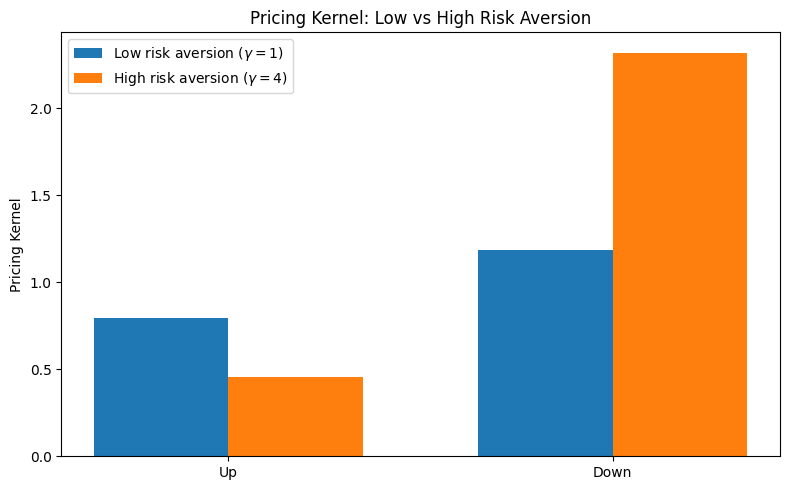

In [10]:
states = ["Up", "Down"]

low_result = model_quantities(1.0)
high_result = model_quantities(4.0)

x = np.arange(len(states))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    low_result["pricing_kernel"],
    width,
    label=r"Low risk aversion ($\gamma=1$)",
)

plt.bar(
    x + width / 2,
    high_result["pricing_kernel"],
    width,
    label=r"High risk aversion ($\gamma=4$)",
)

plt.xticks(x, states)
plt.ylabel("Pricing Kernel")
plt.title("Pricing Kernel: Low vs High Risk Aversion")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Calibration Curve

The calibration can be visualized by plotting the model-implied premium

$$
\pi(\gamma)
=
\mathbb E_P[R_1(\gamma)]
-
R_f(\gamma)
$$

against the coefficient of relative risk aversion.

The target region is

$$
10\%\le\pi(\gamma)\le12\%,
$$

with midpoint

$$
\pi_{\text{target}}=11\%.
$$

The grid search identified an acceptable parameter interval of approximately

$$
1.80\le\gamma\le2.25,
$$

and a point-calibrated value of

$$
\boxed{
\gamma^*=2.02
}
$$

with an implied premium of approximately

$$
\boxed{
11.02\%.
}
$$

The calibration curve shows how the model moves from preference assumptions to an observable target:

$$
\boxed{
\gamma
\rightarrow
m(\gamma)
\rightarrow
\text{equilibrium prices and returns}
\rightarrow
\pi(\gamma).
}
$$

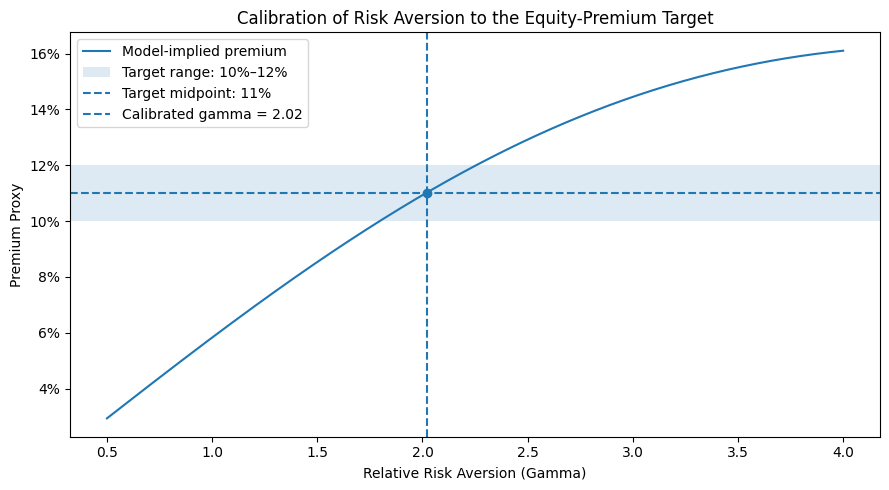

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    calibration_table["gamma"],
    calibration_table["premium"],
    label="Model-implied premium",
)

plt.axhspan(
    target_premium_low,
    target_premium_high,
    alpha=0.15,
    label="Target range: 10%–12%",
)

plt.axhline(
    target_midpoint,
    linestyle="--",
    label="Target midpoint: 11%",
)

plt.axvline(
    calibrated_row["gamma"],
    linestyle="--",
    label=(
        f"Calibrated gamma = "
        f"{calibrated_row['gamma']:.2f}"
    ),
)

plt.scatter(
    [calibrated_row["gamma"]],
    [calibrated_row["premium"]],
    zorder=3,
)

plt.xlabel("Relative Risk Aversion (Gamma)")
plt.ylabel("Premium Proxy")
plt.title(
    "Calibration of Risk Aversion "
    "to the Equity-Premium Target"
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda y, _: f"{y:.0%}"
    )
)

plt.legend()
plt.tight_layout()
plt.show()

## 7. Conclusions and Model Limitations

### Conclusions

This capstone used a two-state representative-agent economy to connect preferences, consumption risk, and equilibrium asset pricing.

The central pricing relationship was

$$
m_s=\beta g_s^{-\gamma},
$$

where the pricing kernel depends on consumption growth and the coefficient of relative risk aversion.

Several results emerged.

First, the low-consumption Down state received greater pricing weight than the high-consumption Up state:

$$
m_d>m_u.
$$

This reflects diminishing marginal utility. Consumption delivered when aggregate consumption is scarce is more valuable.

Second, the pricing kernel determined both safe and risky asset prices through

$$
X_0=\mathbb E_P[mX_1].
$$

The corresponding returns satisfied the Euler equation

$$
\boxed{
1=\mathbb E_P[mR_1].
}
$$

Third, the baseline model with

$$
\gamma=2
$$

produced an implied premium proxy of approximately

$$
10.93\%.
$$

A grid calibration against the illustrative 10%–12% target range produced an acceptable risk-aversion interval of approximately

$$
\boxed{
1.80\le\gamma\le2.25
}
$$

and a midpoint calibration of

$$
\boxed{
\gamma^*=2.02,
}
$$

with an implied premium of approximately

$$
\boxed{
11.02\%.
}
$$

Finally, comparing low and high risk aversion showed that increasing $\gamma$ substantially increases the relative pricing weight of the low-consumption state.

For

$$
\gamma=1,
$$

the Down-to-Up pricing-kernel ratio was approximately

$$
1.50,
$$

while for

$$
\gamma=4,
$$

it increased to approximately

$$
5.06.
$$

The central economic mechanism is therefore

$$
\boxed{
\text{higher risk aversion}
\rightarrow
\text{greater valuation of bad-state consumption}
\rightarrow
\text{different equilibrium prices and expected returns}.
}
$$

### Model Limitations

The numerical results should be interpreted as properties of a deliberately simple teaching model rather than empirical estimates.

In particular:

- the economy contains only two future states;
- physical state probabilities are fixed at 50% each;
- consumption growth is specified rather than estimated from data;
- the risky payoff is stylized rather than derived from an observed security;
- the 10%–12% premium target is an illustrative calibration assumption rather than an empirical estimate;
- only the risk-aversion parameter is calibrated;
- the model is one-period and contains no dynamic trading, transaction costs, estimation error, or changing economic conditions.

The negative risk-free rates generated for some parameter values are therefore model implications of the chosen assumptions, not statements about observed market interest rates.

The calibrated value of $\gamma$ should likewise be interpreted conditionally:

$$
\boxed{
\gamma^*=2.02
}
$$

is the parameter that best matches the selected target inside this particular model, not a universal estimate of investor risk aversion.

Despite its simplicity, the exercise demonstrates the full calibration chain:

$$
\boxed{
\text{preferences}
\rightarrow
\text{pricing kernel}
\rightarrow
\text{asset prices}
\rightarrow
\text{returns}
\rightarrow
\text{risk premium}
\rightarrow
\text{parameter calibration}.
}
$$

## 8. Reproducibility and Validation

The final checks verify the financial identities used throughout the notebook.

The validation tests confirm:

1. physical probabilities sum to one;
2. all modeled consumption-growth values are positive;
3. state prices equal physical probabilities multiplied by the pricing kernel;
4. the risk-free asset price equals the expected pricing kernel;
5. the risk-free Euler equation holds;
6. the risky-asset Euler equation holds;
7. the reusable model function reproduces the direct baseline calculation;
8. the calibrated premium lies inside the target range;
9. the selected calibration is the closest grid point to the 11% midpoint target.

These checks distinguish a notebook that merely executes from one whose key financial relationships are internally consistent.

In [12]:
# Final validation checks

checks = {}

checks["probabilities_sum_to_one"] = np.isclose(
    P.sum(),
    1.0,
)

checks["positive_consumption_growth"] = np.all(
    growth > 0
)

checks["state_price_identity"] = np.allclose(
    state_prices,
    P * pricing_kernel,
)

checks["riskfree_price_identity"] = np.isclose(
    riskfree_price,
    expected_kernel,
)

checks["riskfree_euler"] = np.isclose(
    euler_rf,
    1.0,
)

checks["risky_euler"] = np.isclose(
    euler_risky,
    1.0,
)

function_baseline = model_quantities(
    gamma_baseline
)

checks["function_matches_baseline"] = np.isclose(
    function_baseline["premium"],
    premium_proxy,
)

calibrated_gamma = float(
    calibrated_row["gamma"]
)

calibrated_result = model_quantities(
    calibrated_gamma
)

checks["calibrated_premium_in_range"] = (
    target_premium_low
    <= calibrated_result["premium"]
    <= target_premium_high
)

calibration_errors = (
    calibration_table["premium"]
    .sub(target_midpoint)
    .abs()
)

checks["closest_grid_point_selected"] = (
    calibration_errors.idxmin()
    == best_index
)

for name, passed in checks.items():
    print(f"{name}: {passed}")

assert all(checks.values())

print()
print("All validation checks passed.")

probabilities_sum_to_one: True
positive_consumption_growth: True
state_price_identity: True
riskfree_price_identity: True
riskfree_euler: True
risky_euler: True
function_matches_baseline: True
calibrated_premium_in_range: True
closest_grid_point_selected: True

All validation checks passed.
